[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZacharyHillman18/PharmapyWorkshop/blob/main/Workshop_Notebooks/SyntaxExamples.ipynb)

# PharmaPy syntax examples

A reference notebook with small, runnable examples of the PharmaPy units: reactors and crystallizers in batch, semibatch and continuous mode, **with and without energy balances**. Each example runs in a few seconds. Copy the pattern you need into your own notebook.

## The build recipe
Every unit follows the same order:

1. **Integrator**: a new solver object for every unit, e.g. `ScipyBackend()`
2. **Controller** (optional): what the unit manipulates or prescribes (temperature profile, liquid volume, ...)
3. **Vessel**: `BatchReactor(integrator=..., controller=..., ...)`. Energy-balance options go here (`isothermal`, `adiabatic`, `h_conv`, `diam`)
4. **Phases**: `LiquidPhase(...)`; for crystallizers also `SolidPhase(...)` **with its population-balance mechanism attached first**
5. **Assign phases**: `vessel.Phases = liquid` or `vessel.Phases = [liquid, solid]`
6. **Kinetics** (after the phases): `vessel.RxnKinetics = RxnKinetics(...)` or `vessel.CrystKinetics = CrystKinetics(...)`
7. **Utility / feed** (optional): `vessel.Utility = CoolingWater(...)`, `vessel.Inlet = LiquidStream(...)`
8. **Solve**: `vessel.solve_unit(runtime=...)` or `solve_unit(time_grid=...)`
9. **Results**: `vessel.result.<field>`, e.g. `print(vessel.result)` lists all the fields

## Temperature and energy-balance modes

| Mode | How | Energy balance |
|---|---|---|
| Constant temperature | `isothermal=True` (T of the initial phase) | no |
| Prescribed T profile | `controller=SimpleTemperatureController(temp_func=f)` (batch/semibatch) or `ContinuousVesselController(temp_func=f)` (continuous) | no (a `Utility` is ignored) |
| Jacket / cooling water | no temperature controller, `h_conv=...`, `diam=...` in the vessel, then `vessel.Utility = CoolingWater(mass_flow=..., temp_in=...)` | yes: heat of reaction, feed enthalpy, jacket duty `q_ht` |
| Adiabatic | `adiabatic=True` | yes, without the jacket |
| Continuous, free temperature | `controller=DefaultContinuousVesselVolume()` (the default) holds the volume; add a `Utility` for a jacket | yes |

`h_conv` (vessel side, W/m²/K) must be given to the vessel **before** assigning the `Utility`. The heat-transfer area is $4V_{liq}/d + A_{base}$.

**Running on Google Colab?** Run the next cell first. It installs PharmaPy and puts this notebook's data files and `workshop_utils.py` on the Colab machine (about half a minute). Run it again whenever the runtime restarts. To keep your work, use *File → Save a copy in Drive*. On your own computer the cell skips the install and only unpacks the files.

In [ ]:
# @title Colab setup: run this cell first { display-mode: "form" }
# Installs PharmaPy and unpacks workshop_utils.py and data/ into the working
# directory. Run it again after a runtime restart or a factory reset.
import base64, importlib.metadata, importlib.util, io, os, subprocess, sys, zipfile

if 'google.colab' in sys.modules or importlib.util.find_spec('PharmaPy') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pharmapy-org>=0.3.1'], check=True)

_FILES = (
    '...'
)
with zipfile.ZipFile(io.BytesIO(base64.b64decode(_FILES))) as archive:
    archive.extractall('.')
importlib.invalidate_caches()

try:
    _version = importlib.metadata.version('pharmapy-org')
except importlib.metadata.PackageNotFoundError:   # a development install of PharmaPy
    _version = '(development install)'
print('PharmaPy', _version, '- workshop files ready in', os.getcwd())

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from PharmaPy.Phases_Refactored import LiquidPhase, SolidPhase
from PharmaPy.Streams_Refactored import LiquidStream
from PharmaPy.Reactors_Refactored import BatchReactor, SemiBatchReactor, ContinuousReactor
from PharmaPy.Crystallizers_Refactored import BatchCrystallizer, SemiBatchCrystallizer, ContinuousCrystallizer
from PharmaPy.Mechanisms import OneDFVMMechanism, MomentsPopulationBalance
from PharmaPy.Kinetics import RxnKinetics, CrystKinetics
from PharmaPy.ProcessControl_Refactored import (Controller, SimpleTemperatureController,
                                                ContinuousVesselController, DefaultContinuousVesselVolume)
from PharmaPy.Utilities import CoolingWater
from PharmaPy.IntegratorBackends import ScipyBackend
from PharmaPy.SimExec import SimulationExec

from workshop_utils import apply_pharmapy_patches

apply_pharmapy_patches()

path = 'data/compounds_workshop.json'   # species: A, B, C, D, solvent (the solvent is the last one)

Your PharmaPy version needs no workshop fixes.


---
## 1. Phases and streams

A phase needs **one amount** and **one composition**:

* amount: `vol` (m³), `mass` (kg) or `moles` (kmol)
* composition: `mole_conc` (mol/L) or `mass_conc` (kg/m³), both with `name_solv`, or `mass_frac` / `mole_frac`

Vectors follow the species order of the json file. A stream is the same, with a flow instead of an amount (`vol_flow` in m³/s, `mass_flow` in kg/s, `mole_flow` in kmol/s).

In [2]:
liquid_1 = LiquidPhase(path, temp=313.15, vol=1e-3, mole_conc=[1, 1, 0, 0, 0], name_solv='solvent')
liquid_2 = LiquidPhase(path, temp=313.15, mass=1.0, mass_frac=[0, 0, 0.2, 0, 0.8])

print('liquid_1: mass %.3f kg, mass fractions %s' % (liquid_1.mass, np.round(liquid_1.mass_frac, 3)))
print('liquid_2: volume %.3e m3, mole conc %s mol/L' % (liquid_2.vol, np.round(liquid_2.mole_conc, 3)))

feed = LiquidStream(path, temp=298.15, vol_flow=1e-5, mole_conc=[0, 2, 0, 0, 0], name_solv='solvent')
print('feed: %.2e kg/s' % feed.mass_flow)

liquid_1: mass 0.896 kg, mass fractions [0.112 0.112 0.    0.    0.777]
liquid_2: volume 1.083e-03 m3, mole conc [ 0.     0.     0.923  0.    10.243] mol/L
feed: 9.01e-03 kg/s


A **solid** phase carries its crystal size distribution in a *mechanism*, attached **before** the solid goes into a vessel:

* `OneDFVMMechanism`: finite volumes, full CSD on `x_grid` (µm); `distrib_init` is a number density in #/(µm m³)
* `MomentsPopulationBalance`: moments $\mu_0 \dots \mu_{n-1}$ in µm$^k$/m³; `rad` is the nucleus size (µm)

In [3]:
x_grid = np.geomspace(1, 1500, 60)   # um

solid_fvm = SolidPhase(path, temp=293.15, mass=0, mass_frac=[0, 0, 1, 0, 0])
solid_fvm.mechanisms = OneDFVMMechanism(solid_fvm, target_components='C', solvent_name='solvent',
                                        x_grid=x_grid, distrib_init=np.zeros_like(x_grid))

solid_mom = SolidPhase(path, temp=293.15, mass=0, mass_frac=[0, 0, 1, 0, 0])
solid_mom.mechanisms = MomentsPopulationBalance(owning_phase=solid_mom, target_components='C',
                                                solvent_name='solvent', moments_init=np.zeros(4), rad=1.0)

# Seeds on the FVM grid: give a volume-fraction shape and the seed mass
seed_shape = np.exp(-0.5 * (np.log(x_grid / 100) / 0.15)**2)
solid_seeded = SolidPhase(path, temp=293.15, mass=0, mass_frac=[0, 0, 1, 0, 0])
solid_seeded.mechanisms = OneDFVMMechanism(solid_seeded, target_components='C', solvent_name='solvent',
                                           x_grid=x_grid, distrib_init=seed_shape,
                                           distrib_basis='vol_perc', basis_mass=0.004, vol_slurry=1e-3)

---
## 2. Kinetics

**Reactions**: `RxnKinetics(path, rxn_list, k_params, ea_params, ...)`

* `rxn_list`: strings such as `'A + B --> C'`, with species names from the json file
* `k_params`, `ea_params` (J/mol): Arrhenius parameters, at `temp_ref` if given (else $k = A e^{-E/RT}$)
* `params_f`: reaction orders, one list per reaction for its reactants (default: elementary)
* `delta_hrxn`: heat of reaction, J/mol per reaction (**negative = exothermic**; only used with an energy balance)

**Crystallization**: `CrystKinetics(coeff_solub, nucl_prim, nucl_sec, growth, solubility_type, solubility_basis)`

* `nucl_prim = (k_b, E_b, b)`: #/(m³ s); `nucl_sec = (k_s, E_s, s1, s2)` with $B_s = k_s S^{s_1} (k_v \mu_3)^{s_2}$
* `growth = (k_g, E_g, g)`: µm/s
* `solubility_type='apelblat'`: $c^* = \exp(a_1 + a_2/T + a_3 \ln T)$ in the `solubility_basis` units

Every vessel needs its **own** kinetics object, so we write small functions that return a new one.

In [4]:
def rxn_kinetics(delta_hrxn=(0, 0)):
    return RxnKinetics(path, rxn_list=['A + B --> C', 'B + C --> D'],
                       k_params=[5e-3, 2e-3], ea_params=[40e3, 70e3], temp_ref=333.15,
                       params_f=[[1, 1], [2, 1]],        # r1 = k1 CA CB, r2 = k2 CB^2 CC
                       delta_hrxn=list(delta_hrxn))      # J/mol


def cryst_kinetics():
    return CrystKinetics(np.array([-28.13909202, 0.001, 5.900800253]),
                         nucl_prim=(1.0448e17, 0, 8.30671806),
                         nucl_sec=(0, 0, 0, 0),
                         growth=(2.4297e4, 0, 4.52241037),
                         solubility_type='apelblat', solubility_basis='mass_per_volume_solvent')


print('solubility of C at 273 and 313 K: %.0f and %.0f kg/m3 solvent'
      % (cryst_kinetics().get_solubility(273.15), cryst_kinetics().get_solubility(313.15)))

solubility of C at 273 and 313 K: 143 and 321 kg/m3 solvent


---
## 3. Reactors

### 3a. Batch reactor at constant temperature
`isothermal=True` keeps the temperature of the initial liquid; no energy balance.

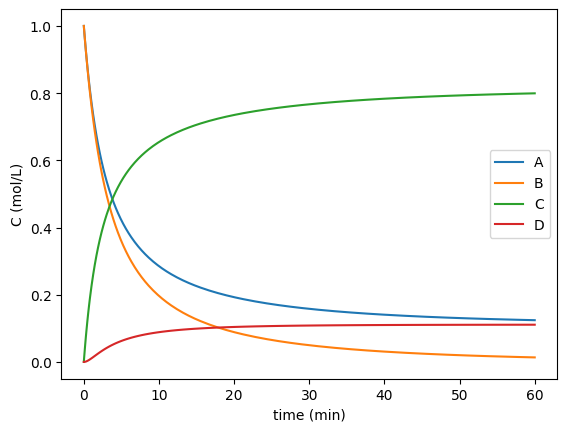

In [5]:
def charge(temp=333.15):
    return LiquidPhase(path, temp=temp, vol=1e-3, mole_conc=[1, 1, 0, 0, 0], name_solv='solvent')


reactor = BatchReactor(integrator=ScipyBackend(), isothermal=True)
reactor.Phases = charge()
reactor.RxnKinetics = rxn_kinetics()
reactor.solve_unit(runtime=3600, verbose=False)

res = reactor.result
plt.plot(res.time / 60, res.mole_conc_liquid0[:, :4])
plt.legend(['A', 'B', 'C', 'D'])
plt.xlabel('time (min)')
plt.ylabel('C (mol/L)')
plt.show()

### 3b. Batch reactor with a temperature profile
A `SimpleTemperatureController` **prescribes** the temperature; no energy balance is solved.

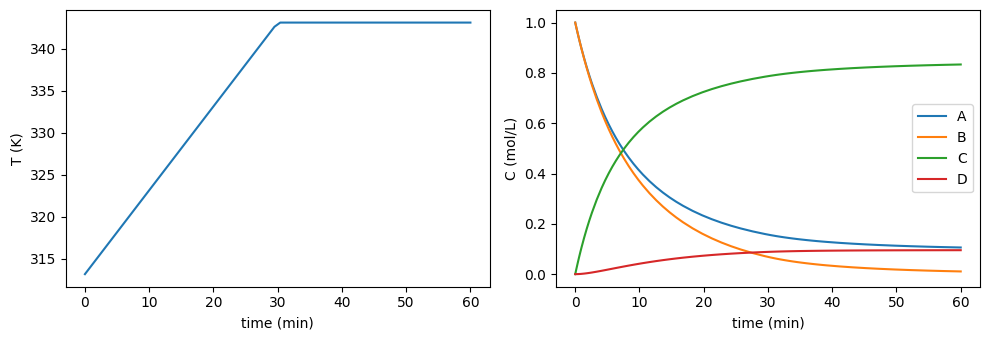

In [6]:
ramp = lambda t: np.interp(t, [0, 1800, 3600], [313.15, 343.15, 343.15])

reactor = BatchReactor(integrator=ScipyBackend(), controller=SimpleTemperatureController(temp_func=ramp))
reactor.Phases = charge(313.15)
reactor.RxnKinetics = rxn_kinetics()
reactor.solve_unit(runtime=3600, verbose=False)

res = reactor.result
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(res.time / 60, res.global_temp)
axes[0].set_ylabel('T (K)')
axes[1].plot(res.time / 60, res.mole_conc_liquid0[:, :4])
axes[1].legend(['A', 'B', 'C', 'D'])
axes[1].set_ylabel('C (mol/L)')
for ax in axes:
    ax.set_xlabel('time (min)')
fig.tight_layout()
plt.show()

### 3c. Batch reactor with an energy balance and a cooling jacket
No temperature controller and `isothermal=False` (the default), so the temperature is a state of the model. The reactions are exothermic (`delta_hrxn`), and the jacket removes heat at a rate $q_{ht} = U A (T - T_{jacket})$, with $1/U = 1/h_{vessel} + 1/h_{utility}$.

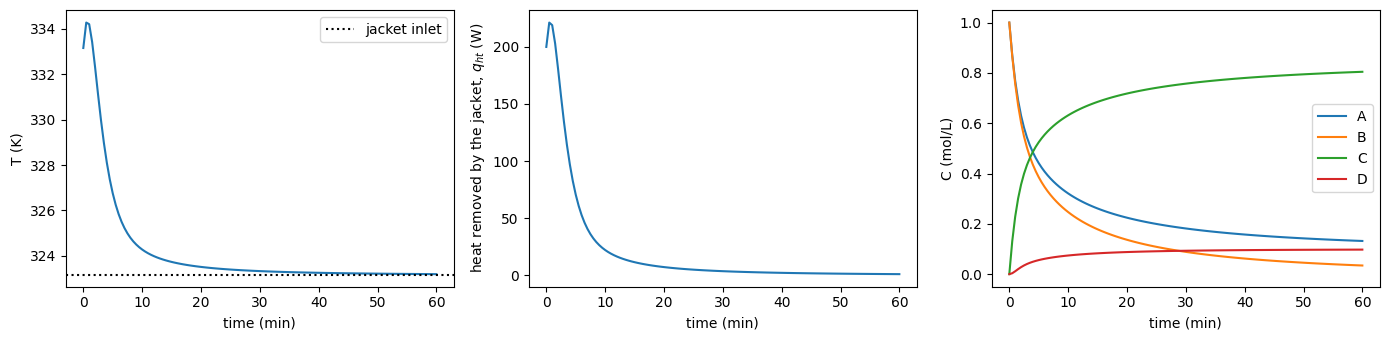

In [7]:
reactor = BatchReactor(integrator=ScipyBackend(), h_conv=1000, diam=0.1)   # h_conv [W/m2/K], diam [m]
reactor.Phases = charge(333.15)
reactor.RxnKinetics = rxn_kinetics(delta_hrxn=(-60e3, -40e3))             # exothermic, J/mol
reactor.Utility = CoolingWater(mass_flow=0.1, temp_in=323.15)              # jacket inlet: 0.1 kg/s at 50 C
reactor.solve_unit(time_grid=np.linspace(0, 3600, 121), verbose=False)

res = reactor.result
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(res.time / 60, res.global_temp)
axes[0].axhline(323.15, color='k', ls=':', label='jacket inlet')
axes[0].set_ylabel('T (K)')
axes[0].legend()
axes[1].plot(res.time / 60, res.q_ht)
axes[1].set_ylabel('heat removed by the jacket, $q_{ht}$ (W)')
axes[2].plot(res.time / 60, res.mole_conc_liquid0[:, :4])
axes[2].legend(['A', 'B', 'C', 'D'])
axes[2].set_ylabel('C (mol/L)')
for ax in axes:
    ax.set_xlabel('time (min)')
fig.tight_layout()
plt.show()

### 3d. Adiabatic batch reactor
`adiabatic=True`: the energy balance is solved but there is no heat exchange. With a single reaction, the temperature rise can be checked by hand: $\Delta T_{ad} = (-\Delta H_r)\, n_{reacted} / \sum_j m_j c_{p,j}$.

In [8]:
reactor = BatchReactor(integrator=ScipyBackend(), adiabatic=True)
reactor.Phases = charge(313.15)
reactor.RxnKinetics = RxnKinetics(path, rxn_list=['A + B --> C'], k_params=[5e-3], ea_params=[40e3],
                                  temp_ref=313.15, delta_hrxn=[-50e3])
reactor.solve_unit(time_grid=np.linspace(0, 3 * 3600, 61), verbose=False)
res = reactor.result

# hand check (cp in J/mol/K from the json file: A, B, C constant; solvent is a polynomial in T)
mw = np.array([100, 100, 200, 300, 72.107])
temp_avg = res.global_temp[[0, -1]].mean()
cp_molar = np.array([200, 200, 400, 600, np.polyval([1.8275e-6, -1.2686e-3, 0.40257, 63.393], temp_avg)])
mass_avg = res.mass_j_liquid0[[0, -1]].mean(axis=0)
n_reacted = (res.mass_j_liquid0[0, 0] - res.mass_j_liquid0[-1, 0]) / mw[0] * 1000   # mol of A
dT_hand = 50e3 * n_reacted / np.sum(mass_avg * cp_molar / mw * 1000)

print('simulated temperature rise: %.2f K,  hand calculation: %.2f K' % (res.global_temp[-1] - res.global_temp[0], dT_hand))

simulated temperature rise: 31.26 K,  hand calculation: 31.27 K


### 3e. Semibatch reactor (dosing)
Same as batch, plus an `Inlet`. Here B is dosed into a charge of A at constant temperature.

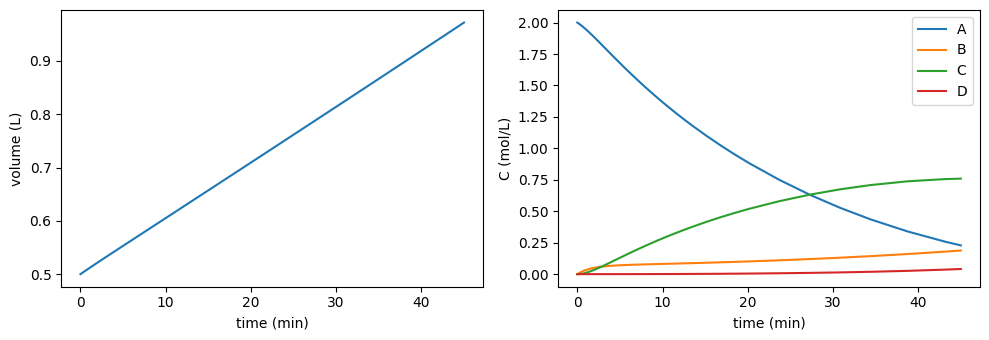

In [9]:
reactor = SemiBatchReactor(integrator=ScipyBackend(), controller=SimpleTemperatureController(temp_func=lambda t: 333.15))
reactor.Phases = LiquidPhase(path, temp=333.15, vol=0.5e-3, mole_conc=[2, 0, 0, 0, 0], name_solv='solvent')
reactor.RxnKinetics = rxn_kinetics()
reactor.Inlet = LiquidStream(path, temp=333.15, vol_flow=0.5e-3 / 2700, mole_conc=[0, 2, 0, 0, 0], name_solv='solvent')
reactor.solve_unit(runtime=2700, verbose=False)

res = reactor.result
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(res.time / 60, res.vessel_vol * 1e3)
axes[0].set_ylabel('volume (L)')
axes[1].plot(res.time / 60, res.mole_conc_liquid0[:, :4])
axes[1].legend(['A', 'B', 'C', 'D'])
axes[1].set_ylabel('C (mol/L)')
for ax in axes:
    ax.set_xlabel('time (min)')
fig.tight_layout()
plt.show()

### 3f. Continuous reactor (CSTR)
A continuous unit needs a controller that sets its outlet flow:

* `ContinuousVesselController(temp_func=f)`: holds the volume **and** prescribes the temperature (no energy balance)
* `DefaultContinuousVesselVolume()` (the default): holds the volume only, so the temperature comes from the energy balance (here with an exothermic reaction and a jacket)

The residence time is $\tau = V/Q$; the vessel starts full of solvent and approaches steady state.

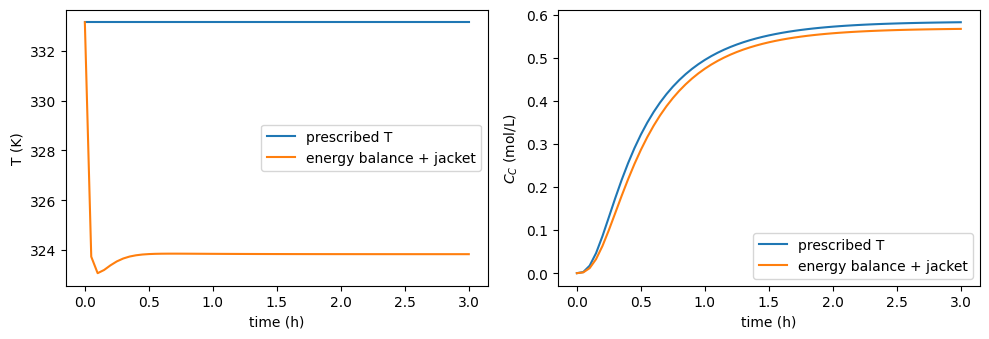

outlet flow at the end: 5.42e-07 m3/s (feed 5.56e-07 m3/s)


In [10]:
def cstr_feed():
    return LiquidStream(path, temp=313.15, vol_flow=1e-3 / 1800, mole_conc=[1, 1, 0, 0, 0], name_solv='solvent')


def solvent_charge(temp):
    return LiquidPhase(path, temp=temp, vol=1e-3, mole_conc=[0, 0, 0, 0, 0], name_solv='solvent')


# (i) prescribed temperature
cstr_1 = ContinuousReactor(integrator=ScipyBackend(),
                           controller=ContinuousVesselController(temp_func=lambda t: 333.15))
cstr_1.Phases = solvent_charge(333.15)
cstr_1.RxnKinetics = rxn_kinetics()
cstr_1.Inlet = cstr_feed()
cstr_1.solve_unit(time_grid=np.linspace(0, 6 * 1800, 61), verbose=False)

# (ii) energy balance: exothermic reaction, 313 K feed, jacket at 323 K
cstr_2 = ContinuousReactor(integrator=ScipyBackend(), h_conv=1000, diam=0.1,
                           controller=DefaultContinuousVesselVolume())
cstr_2.Phases = solvent_charge(333.15)
cstr_2.RxnKinetics = rxn_kinetics(delta_hrxn=(-60e3, -40e3))
cstr_2.Inlet = cstr_feed()
cstr_2.Utility = CoolingWater(mass_flow=0.1, temp_in=323.15)
cstr_2.solve_unit(time_grid=np.linspace(0, 6 * 1800, 61), verbose=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for unit, label in [(cstr_1, 'prescribed T'), (cstr_2, 'energy balance + jacket')]:
    res = unit.result
    axes[0].plot(res.time / 3600, res.global_temp, label=label)
    axes[1].plot(res.time / 3600, res.mole_conc_liquid0[:, 2], label=label)
axes[0].set_ylabel('T (K)')
axes[1].set_ylabel('$C_C$ (mol/L)')
for ax in axes:
    ax.set_xlabel('time (h)')
    ax.legend()
fig.tight_layout()
plt.show()
print('outlet flow at the end: %.2e m3/s (feed %.2e m3/s)' % (cstr_2.result.outlet_vol_flow[-1], 1e-3 / 1800))

---
## 4. Crystallizers

Crystallizers follow the same recipe; the differences are the **solid phase with a mechanism** and `CrystKinetics`. The model has no heat of crystallization, so with an energy balance the temperature is set by the jacket, the feed and the heat capacity (including the crystals, via `cp_solid` in the json file).

### 4a. Batch cooling crystallizer, prescribed temperature profile (FVM)

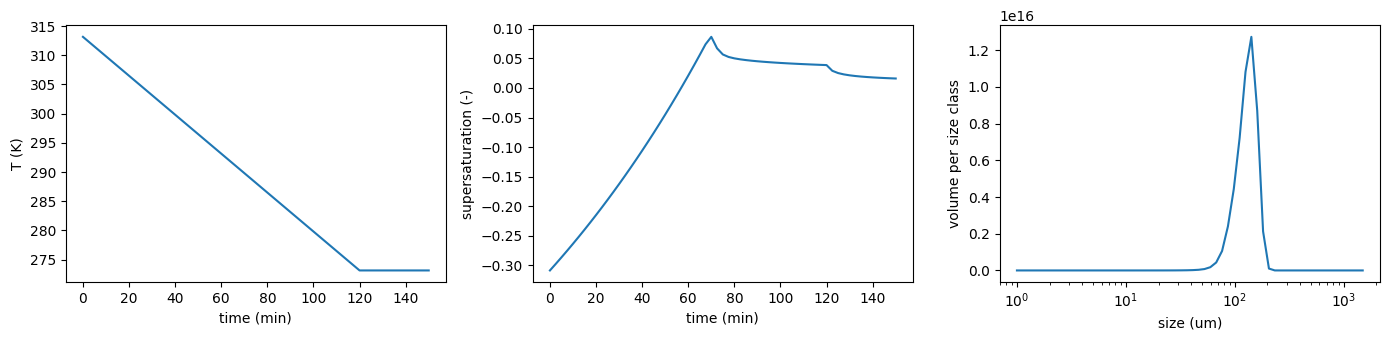

In [11]:
def fresh_solution(temp=313.15):
    return LiquidPhase(path, temp=temp, mass=1.0, mass_frac=[0, 0, 0.2, 0, 0.8], name_solv='solvent')


def fvm_solid(temp):
    solid = SolidPhase(path, temp=temp, mass=0, mass_frac=[0, 0, 1, 0, 0])
    solid.mechanisms = OneDFVMMechanism(solid, target_components='C', solvent_name='solvent',
                                        x_grid=x_grid, distrib_init=np.zeros_like(x_grid))
    return solid


cooling = lambda t: np.interp(t, [0, 7200], [313.15, 273.15])

cryst = BatchCrystallizer(integrator=ScipyBackend(options={'maxh': 60}),
                          controller=SimpleTemperatureController(temp_func=cooling))
cryst.Phases = [fresh_solution(), fvm_solid(313.15)]     # 1) mechanism on the solid, 2) Phases, 3) kinetics
cryst.CrystKinetics = cryst_kinetics()
cryst.solve_unit(time_grid=np.linspace(0, 9000, 61), verbose=False)

res = cryst.result
mech = cryst.Phases.Solids[0].mechanisms[0]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(res.time / 60, res.global_temp)
axes[0].set_ylabel('T (K)')
axes[1].plot(res.time / 60, np.ravel(res.supersat))
axes[1].set_ylabel('supersaturation (-)')
axes[2].semilogx(x_grid, res.distrib_solid0[-1] * x_grid**3 * mech.dx)
axes[2].set_xlabel('size (um)')
axes[2].set_ylabel('volume per size class')
axes[0].set_xlabel('time (min)')
axes[1].set_xlabel('time (min)')
fig.tight_layout()
plt.show()

### 4b. The same batch with the method of moments
Only the mechanism changes. The result field is `mu_n_solid0` (µm$^k$/m³), and the mean size is $\mu_1/\mu_0$.

In [12]:
def moments_solid(temp, moments_init=None):
    solid = SolidPhase(path, temp=temp, mass=0, mass_frac=[0, 0, 1, 0, 0])
    solid.mechanisms = MomentsPopulationBalance(owning_phase=solid, target_components='C', solvent_name='solvent',
                                                moments_init=np.zeros(4) if moments_init is None else moments_init,
                                                rad=1.0)
    return solid


cryst = BatchCrystallizer(integrator=ScipyBackend(options={'maxh': 60}),
                          controller=SimpleTemperatureController(temp_func=cooling))
cryst.Phases = [fresh_solution(), moments_solid(313.15)]
cryst.CrystKinetics = cryst_kinetics()
cryst.solve_unit(time_grid=np.linspace(0, 9000, 61), verbose=False)

mu = cryst.result.mu_n_solid0
print('final mean size mu1/mu0 = %.1f um, crystals formed: %.3f kg' % (mu[-1, 1] / mu[-1, 0], cryst.Phases.Solids[0].mass))

final mean size mu1/mu0 = 106.0 um, crystals formed: 0.069 kg


### 4c. Batch crystallizer cooled by a jacket (energy balance)
No temperature controller: the jacket at a constant 268 K cools the slurry, and the temperature follows from the energy balance. A small heat-transfer coefficient gives a cooling time scale of about $m c_p / UA \approx$ 20 min.

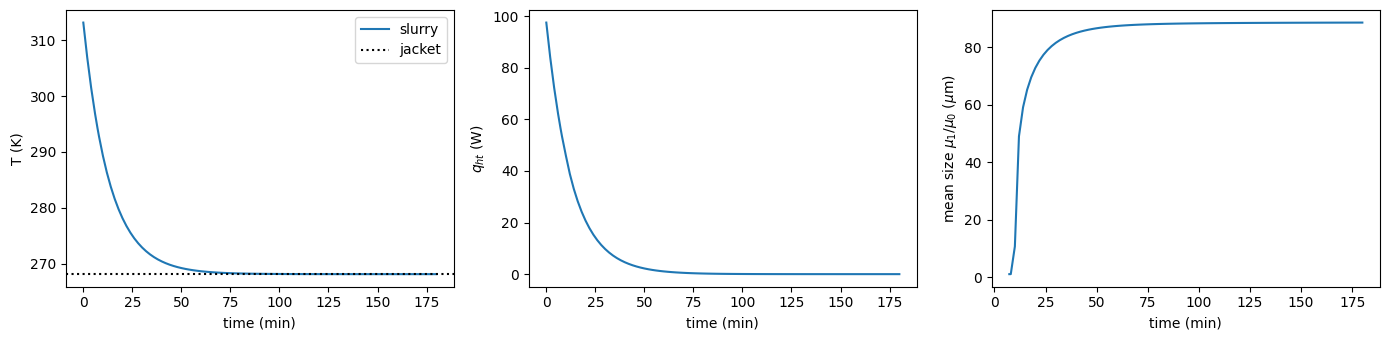

In [13]:
cryst = BatchCrystallizer(integrator=ScipyBackend(options={'maxh': 60}), h_conv=100, diam=0.1)
cryst.Phases = [fresh_solution(313.15), moments_solid(313.15)]
cryst.CrystKinetics = cryst_kinetics()
cryst.Utility = CoolingWater(mass_flow=0.1, temp_in=268.15, h_conv=100)
cryst.solve_unit(time_grid=np.linspace(0, 3 * 3600, 91), verbose=False)

res = cryst.result
mu = res.mu_n_solid0
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(res.time / 60, res.global_temp, label='slurry')
axes[0].axhline(268.15, color='k', ls=':', label='jacket')
axes[0].set_ylabel('T (K)')
axes[0].legend()
axes[1].plot(res.time / 60, res.q_ht)
axes[1].set_ylabel('$q_{ht}$ (W)')
has_crystals = mu[:, 0] > 0
axes[2].plot(res.time[has_crystals] / 60, mu[has_crystals, 1] / mu[has_crystals, 0])
axes[2].set_ylabel(r'mean size $\mu_1/\mu_0$ ($\mu$m)')
for ax in axes:
    ax.set_xlabel('time (min)')
fig.tight_layout()
plt.show()

### 4d. Advanced: a jacket temperature ramp (custom controller)
`CoolingWater.temp_in` is a constant, and the built-in controllers either prescribe the vessel temperature or do nothing to the jacket. A small `Controller` subclass can change the jacket inlet temperature at every step. Because it does **not** own the vessel temperature, the energy balance stays active and the slurry follows the jacket with a lag.

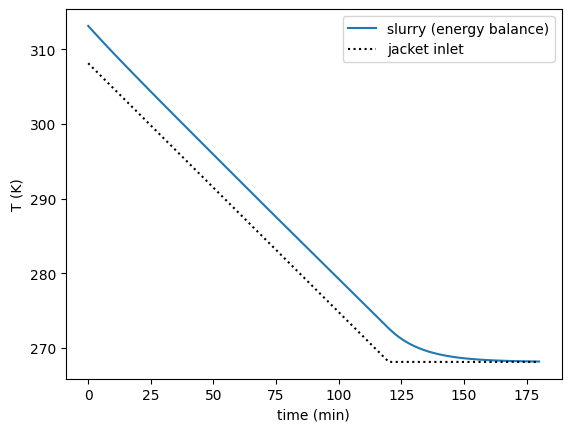

In [14]:
class JacketProfile(Controller):
    """Sets the utility inlet temperature from a function of time."""

    def __init__(self, jacket_temp_func):
        super().__init__()
        self.jacket_temp_func = jacket_temp_func

    def update_state(self, time, completed_state, unit):
        unit.Utility.temp_in = self.jacket_temp_func(time)


jacket_ramp = lambda t: np.interp(t, [0, 7200], [308.15, 268.15])

cryst = BatchCrystallizer(integrator=ScipyBackend(options={'maxh': 60}), h_conv=100, diam=0.1,
                          controller=JacketProfile(jacket_ramp))
cryst.Phases = [fresh_solution(313.15), moments_solid(313.15)]
cryst.CrystKinetics = cryst_kinetics()
cryst.Utility = CoolingWater(mass_flow=0.1, temp_in=jacket_ramp(0), h_conv=100)
cryst.solve_unit(time_grid=np.linspace(0, 3 * 3600, 91), verbose=False)

res = cryst.result
plt.plot(res.time / 60, res.global_temp, label='slurry (energy balance)')
plt.plot(res.time / 60, jacket_ramp(res.time), 'k:', label='jacket inlet')
plt.xlabel('time (min)')
plt.ylabel('T (K)')
plt.legend()
plt.show()

### 4e. Continuous crystallizer (MSMPR)
As for the CSTR, the controller sets the outlet flow. The crystallizer is started full of solution saturated at its temperature (this avoids a large nucleation burst at $t = 0$).

* (i) `ContinuousVesselController`: prescribed temperature
* (ii) `DefaultContinuousVesselVolume` + jacket: the temperature comes from the energy balance (hot feed, cold jacket)

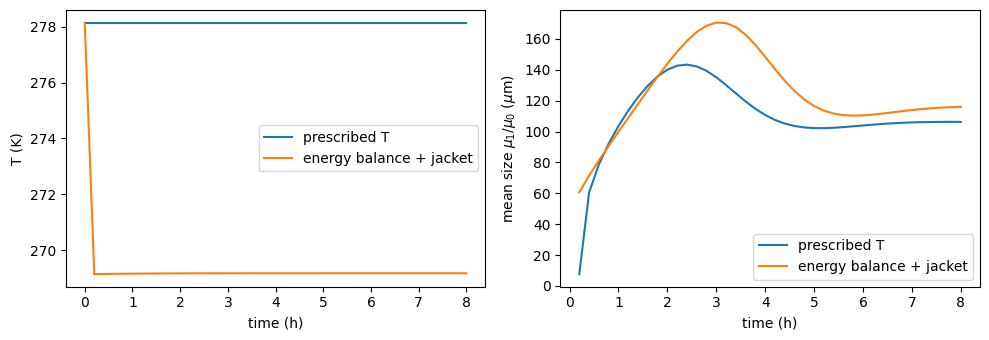

In [15]:
def saturated_solution(temp, vol):
    c_sat = cryst_kinetics().get_solubility(temp)          # kg C / m3 solvent
    w_sat = c_sat / (c_sat + 887.6)
    return LiquidPhase(path, temp=temp, vol=vol, mass_frac=[0, 0, w_sat, 0, 1 - w_sat], name_solv='solvent')


def msmpr_feed():
    return LiquidStream(path, temp=313.15, vol_flow=1e-3 / 3600, mass_frac=[0, 0, 0.2, 0, 0.8], name_solv='solvent')


# (i) prescribed temperature
msmpr_1 = ContinuousCrystallizer(integrator=ScipyBackend(options={'maxh': 600}),
                                 controller=ContinuousVesselController(temp_func=lambda t: 278.15))
msmpr_1.Phases = [saturated_solution(278.15, 1e-3), moments_solid(278.15)]
msmpr_1.CrystKinetics = cryst_kinetics()
msmpr_1.Inlet = msmpr_feed()
msmpr_1.solve_unit(time_grid=np.linspace(0, 8 * 3600, 41), verbose=False)

# (ii) energy balance with a cold jacket
msmpr_2 = ContinuousCrystallizer(integrator=ScipyBackend(options={'maxh': 600}), h_conv=1000, diam=0.1,
                                 controller=DefaultContinuousVesselVolume())
msmpr_2.Phases = [saturated_solution(278.15, 1e-3), moments_solid(278.15)]
msmpr_2.CrystKinetics = cryst_kinetics()
msmpr_2.Inlet = msmpr_feed()
msmpr_2.Utility = CoolingWater(mass_flow=0.1, temp_in=268.15)
msmpr_2.solve_unit(time_grid=np.linspace(0, 8 * 3600, 41), verbose=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for unit, label in [(msmpr_1, 'prescribed T'), (msmpr_2, 'energy balance + jacket')]:
    res = unit.result
    mu = res.mu_n_solid0
    has_crystals = mu[:, 0] > 1e-6 * mu[-1, 0]
    axes[0].plot(res.time / 3600, res.global_temp, label=label)
    axes[1].plot(res.time[has_crystals] / 3600, mu[has_crystals, 1] / mu[has_crystals, 0], label=label)
axes[0].set_ylabel('T (K)')
axes[1].set_ylabel(r'mean size $\mu_1/\mu_0$ ($\mu$m)')
for ax in axes:
    ax.set_xlabel('time (h)')
    ax.legend()
fig.tight_layout()
plt.show()

### 4f. Semibatch crystallizer
Same as batch, plus an `Inlet`: here a hot, concentrated solution is fed into a cold, saturated heel.

In [16]:
cryst = SemiBatchCrystallizer(integrator=ScipyBackend(options={'maxh': 600}),
                              controller=SimpleTemperatureController(temp_func=lambda t: 278.15))
cryst.Phases = [saturated_solution(278.15, 0.2e-3), moments_solid(278.15)]
cryst.CrystKinetics = cryst_kinetics()
cryst.Inlet = LiquidStream(path, temp=313.15, vol_flow=1e-3 / 3600, mass_frac=[0, 0, 0.2, 0, 0.8], name_solv='solvent')
cryst.solve_unit(time_grid=np.linspace(0, 3600, 31), verbose=False)

res = cryst.result
print('volume: %.2f -> %.2f L, crystals: %.3f kg' % (res.vessel_vol[0] * 1e3, res.vessel_vol[-1] * 1e3,
                                                      cryst.Phases.Solids[0].mass))

volume: 0.20 -> 1.19 L, crystals: 0.045 kg


---
## 5. Flowsheets
`SimulationExec` connects units in series with a flowsheet string. Only the **first** unit gets an `Inlet`; downstream units need placeholder `Phases` (for crystallizers: `[liquid, solid]`), which are replaced by the upstream material. Per-unit solver arguments go in `kwargs_run`.

* batch → batch: the final liquid of the reactor is charged to the crystallizer
* continuous → continuous (or → semibatch): the whole time-dependent outlet is passed on

In [17]:
# Batch reactor -> batch crystallizer (cooling from 333 K to 273 K)
flst = SimulationExec(path, flowsheet='R01 --> CR01')

flst.R01 = BatchReactor(integrator=ScipyBackend(), isothermal=True)
flst.R01.Phases = LiquidPhase(path, temp=333.15, vol=1e-3, mole_conc=[1.4, 1.4, 0, 0, 0], name_solv='solvent')
flst.R01.RxnKinetics = rxn_kinetics()

flst.CR01 = BatchCrystallizer(integrator=ScipyBackend(options={'maxh': 60}),
                              controller=SimpleTemperatureController(temp_func=lambda t: np.interp(t, [0, 3600], [333.15, 273.15])))
flst.CR01.Phases = [LiquidPhase(path, temp=333.15, vol=1e-3, mole_conc=[0, 0, 0, 0, 0], name_solv='solvent'),
                    moments_solid(333.15)]
flst.CR01.CrystKinetics = cryst_kinetics()

flst.SolveFlowsheet(kwargs_run={'R01': {'runtime': 3600, 'verbose': False},
                                'CR01': {'runtime': 5400, 'verbose': False}}, verbose=False)

mu = flst.CR01.result.mu_n_solid0[-1]
print('C in the reactor product: %.3f kg; crystals: %.3f kg, mean size %.1f um'
      % (flst.R01.result.mass_j_liquid0[-1, 2], flst.CR01.Phases.Solids[0].mass, mu[1] / mu[0]))

C in the reactor product: 0.205 kg; crystals: 0.103 kg, mean size 105.5 um


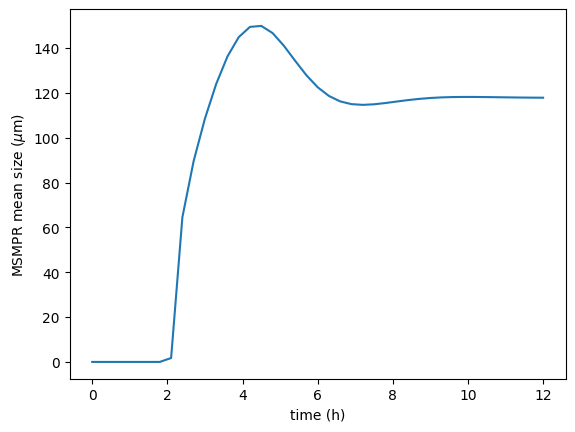

In [18]:
# CSTR -> MSMPR (continuous): same horizon for both units
flst = SimulationExec(path, flowsheet='R01 --> CR01')

flst.R01 = ContinuousReactor(integrator=ScipyBackend(),
                             controller=ContinuousVesselController(temp_func=lambda t: 333.15))
flst.R01.Phases = solvent_charge(333.15)
flst.R01.RxnKinetics = rxn_kinetics()
flst.R01.Inlet = LiquidStream(path, temp=333.15, vol_flow=1e-3 / 3600, mole_conc=[1.4, 1.4, 0, 0, 0], name_solv='solvent')

flst.CR01 = ContinuousCrystallizer(integrator=ScipyBackend(options={'maxh': 600}),
                                   controller=ContinuousVesselController(temp_func=lambda t: 273.15))
flst.CR01.Phases = [saturated_solution(273.15, 1e-3), moments_solid(273.15)]
flst.CR01.CrystKinetics = cryst_kinetics()

time_grid = np.linspace(0, 12 * 3600, 41)
flst.SolveFlowsheet(kwargs_run={'R01': {'time_grid': time_grid, 'verbose': False},
                                'CR01': {'time_grid': time_grid, 'verbose': False}}, verbose=False)

res = flst.CR01.result          # result.time can contain extra points (events), so plot against it
mu = res.mu_n_solid0
plt.plot(res.time / 3600, mu[:, 1] / np.maximum(mu[:, 0], 1e-30))
plt.xlabel('time (h)')
plt.ylabel(r'MSMPR mean size ($\mu$m)')
plt.show()

---
## 6. Results
`print(unit.result)` lists the available fields. The most common ones:

| Field | Meaning | Units |
|---|---|---|
| `time` | time points | s |
| `mass_j_liquid0` | species masses in the liquid (solver state) | kg |
| `mole_conc_liquid0` | species concentrations | mol/L (= kmol/m³) |
| `global_temp` | temperature (a state when the energy balance is solved) | K |
| `q_ht` | heat removed by the jacket (only with a `Utility`) | W |
| `vessel_vol`, `Total_m_in_vessel` | volume and total mass in the vessel | m³, kg |
| `outlet_vol_flow` | outlet flow (continuous units) | m³/s |
| `distrib_solid0` | number density on `x_grid` (FVM) | #/(µm m³) |
| `mu_n_solid0` | moments (method of moments) | µm$^k$/m³ |
| `supersat`, `solubility` | relative supersaturation, solubility | -, per `solubility_basis` |

The final state is also available on the phases, e.g. `unit.Phases.Solids[0].mass` (kg of crystals).

In [19]:
print(msmpr_2.result)

------------------------
PharmaPy result object
------------------------

Fields shown in the tables below can be accessed as result.<field>, e.g. result.mass_j_liquid0 

---------------------------------------------------------
states           dim   units         index                  
---------------------------------------------------------
mass_j_liquid0   5     kg            A, B, C, D, solvent    
global_temp      1     K                                    
mu_n_solid0      4     micron**n     0, ..., 3              
---------------------------------------------------------

----------------------------------------------------------
f(states)           dim   units       index                  
----------------------------------------------------------
Total_m_in_vessel   1     kg/s                               
vessel_vol          1     m3                                 
outlet_vol_flow     1     m3/s                               
mole_conc_liquid0   5     kmol/m3     A, B, 